**Outcome.** `models/forecaster/lightgbm/`, `models/risk_scorer/lightgbm/` and the weather and EV models `models/forecaster/lightgbm_weather/`, `models/risk_scorer/lightgbm_weather_ev/`: LightGBM text model, `metadata.json`, and `parity/` CSVs that `tests/ml/test_parity.py` must reproduce.

In [1]:
import hashlib
import json
import platform
from datetime import date

import lightgbm as lgb
import numpy as np
import pandas as pd
import sklearn
from _data import DATA_DIR, HOLIDAYS, MODELS_DIR, holdout_start, load_tables
from _features import LOAD_FEATURES, RISK_FEATURES, load_features, risk_features, to_grid, trip_labels
from _models import SEED, day_ahead, fit_load_model, load_table, read_result, recall_and_false_alarms, risk_examples, rolling_day_ahead
from _style import COLORS, label
import plotly.express as px

tables = load_tables()
load, transformers = tables["load"], tables["transformers"]
cutoff = holdout_start(load)
holdout_days = pd.date_range(cutoff, periods=7, freq="D")
load_choice, risk_choice = read_result("04_load_forecast"), read_result("05_risk")
print(f"held-out week: {holdout_days[0]:%Y-%m-%d} to {holdout_days[-1]:%Y-%m-%d}")

held-out week: 2026-05-20 to 2026-05-26


## Retrain the load forecast on every training day
Every feature is at least one day old, so the features of a held-out day are exactly what a 00:00 forecast for that day would see.

In [2]:
table = load_table(load, HOLIDAYS)
table = table[table["ts"] >= table["ts"].min() + pd.Timedelta(days=7)]
train_table = table[table["ts"] < cutoff]
load_model = fit_load_model(train_table, load_choice["params"])
holdout_forecast = day_ahead(load_model, table[table["ts"] >= cutoff])
print(f"trained on {len(train_table.dropna(subset=['transformer_kw'])):,} intervals up to {train_table['ts'].max()}")

trained on 203,808 intervals up to 2026-05-19 23:45:00+08:00


## Seasonal naive, exactly as `silip_ml` computes it
Same slot last week; a missing slot falls back to that transformer's mean over the week before the forecast day.

In [3]:
grid = to_grid(load)
naive = []
for day in holdout_days:
    last_week = grid.loc[day - pd.Timedelta(days=7) : day - pd.Timedelta(minutes=15)]
    guess = last_week.iloc[:96].reset_index(drop=True).fillna(last_week.mean())
    guess.index = pd.date_range(day, periods=96, freq="15min")
    naive.append(guess.stack(future_stack=True).rename("kw_pred").rename_axis(["ts", "transformer_id"]).reset_index())
naive = pd.concat(naive, ignore_index=True)

actual = load[load["ts"] >= cutoff][["transformer_id", "ts", "transformer_kw"]]


def load_mae(forecast: pd.DataFrame) -> tuple[float, int]:
    joined = forecast.merge(actual, on=["transformer_id", "ts"])
    return float((joined["kw_pred"] - joined["transformer_kw"]).abs().mean()), len(joined)


mae_naive, n_intervals = load_mae(naive)
mae_lgbm, _ = load_mae(holdout_forecast)
print(f"held-out load MAE: seasonal naive {mae_naive:.3f} kW, LightGBM {mae_lgbm:.3f} kW over {n_intervals:,} intervals")

held-out load MAE: seasonal naive 7.797 kW, LightGBM 4.663 kW over 33,462 intervals

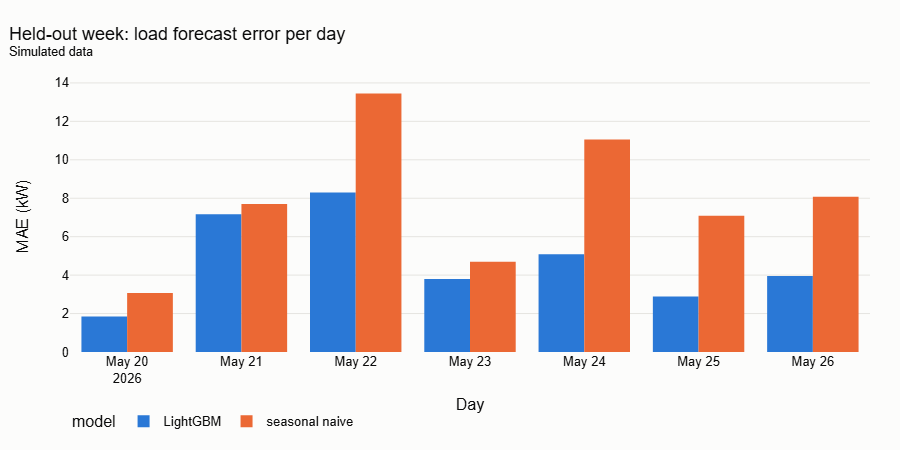

In [4]:
daily = pd.concat([
    holdout_forecast.merge(actual).assign(model="LightGBM"),
    naive.merge(actual).assign(model="seasonal naive"),
])
daily["abs_error"] = (daily["kw_pred"] - daily["transformer_kw"]).abs()
daily = daily.groupby([daily["ts"].dt.normalize().rename("day"), "model"])["abs_error"].mean().reset_index()
fig = px.bar(daily, x="day", y="abs_error", color="model", barmode="group", color_discrete_sequence=COLORS)
label(fig, "Held-out week: load forecast error per day", "Day", "MAE (kW)").show()

Takeaway: LightGBM wins on every held-out day. Its worst day is the typhoon (May 22): no lag can see a storm coming.

## Retrain the risk model on every training day
As in `05`: features come from out-of-sample day-ahead forecasts (weekly refits), labels from the trip rule on true load.

In [5]:
first_day = pd.Timestamp(risk_choice["first_training_day"])
labels = trip_labels(load, transformers)
train_forecasts = rolling_day_ahead(table, load_choice["params"], first_day, cutoff)
train_examples = risk_examples(train_forecasts, transformers, labels)
risk_model = lgb.LGBMClassifier(**risk_choice["params"], random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)
risk_model.fit(train_examples[RISK_FEATURES].to_numpy(dtype=np.float64), train_examples["tripped"].astype(int))
thresholds = risk_choice["thresholds"]
print(f"{len(train_examples):,} training transformer-days, {int(train_examples['tripped'].sum())} trips; thresholds {thresholds}")

1,785 training transformer-days, 207 trips; thresholds {'critical': 0.07, 'watch': 0.04}


In [6]:
holdout_examples = risk_examples(holdout_forecast, transformers, labels)
score = risk_model.booster_.predict(holdout_examples[RISK_FEATURES].to_numpy(dtype=np.float64))
flag_model = pd.Series(score >= thresholds["critical"], index=holdout_examples.index)
flag_rules = holdout_examples["hours_over_100"] * 4 >= 8
risk_model_metrics = recall_and_false_alarms(flag_model, holdout_examples["tripped"])
risk_rules_metrics = recall_and_false_alarms(flag_rules, holdout_examples["tripped"])
lead_h = (holdout_examples["trip_ts"] - holdout_examples["day"]).dt.total_seconds() / 3600
early = holdout_examples["tripped"] & (lead_h >= 12)

## Held-out results (Simulated)
The run-backtest report format. Risk rows use the LightGBM load forecast for both scorers, so the comparison isolates the scorer. Outage rows are unchanged by this notebook; `make backtest` reports them.

In [7]:
report = pd.DataFrame([
    ["Risk recall, next 24 h scored at 00:00", risk_rules_metrics["recall"], risk_model_metrics["recall"], f"{risk_rules_metrics['trips']} trips"],
    ["Risk recall at >= 12 h lead", (flag_rules & early).sum() / early.sum(), (flag_model & early).sum() / early.sum(), f"{int(early.sum())} trips"],
    ["False alarms per transformer-month", risk_rules_metrics["false_alarms_per_tx_month"], risk_model_metrics["false_alarms_per_tx_month"], f"{risk_rules_metrics['windows']} transformer-days"],
    ["Load MAE (kW)", mae_naive, mae_lgbm, f"{n_intervals:,} intervals"],
], columns=["Metric (Simulated)", "Baseline", "Strategy", "n"])
report.insert(1, "Baseline name", ["rules", "rules", "rules", "seasonal_naive"])
report.insert(3, "Strategy name", ["lightgbm"] * 4)
report.round(3)

,Metric (Simulated),Baseline name,Baseline,Strategy name,Strategy,n
0,"Risk recall, next 24 h scored at 00:00",rules,0.960,lightgbm,1.000,25 trips
1,Risk recall at >= 12 h lead,rules,0.960,lightgbm,1.000,25 trips
2,False alarms per transformer-month,rules,8.235,lightgbm,9.916,357 transformer-days
3,Load MAE (kW),seasonal_naive,7.797,lightgbm,4.663,"33,462 intervals"


## Keep only what beats its baseline
Load: lower MAE. Risk: higher recall *and* no more false alarms than the rules (the budget set in `05`). A model that fails is still exported, so the strategy stays runnable and guarded by the parity test, but its metadata says `kept: false` and the configured default stays the baseline.

In [8]:
keep_load = mae_lgbm < mae_naive
keep_risk = (risk_model_metrics["recall"] > risk_rules_metrics["recall"]) and (
    risk_model_metrics["false_alarms_per_tx_month"] <= risk_rules_metrics["false_alarms_per_tx_month"]
)
print(f"keep load forecast: {keep_load}; keep risk model: {keep_risk}")
assert keep_load, "the load forecast lost to seasonal naive on the held-out week; do not ship it"

keep load forecast: True; keep risk model: False


Takeaway: the load forecast clearly wins. The risk model catches every held-out trip (one more than the rules) but raises a few more false alarms, so it does not strictly beat the rules: it is exported as a candidate (`kept: false`) and `RISK_SCORER=rules` stays the default. The threshold was not re-tuned on the held-out week; doing so would make this check meaningless.

## Export
LightGBM native text (never pickle) plus `metadata.json`: features, parameters, training window, data seed and fingerprint, metrics, library versions. `silip_ml` reads the feature list and parameters from here, never from a hardcoded copy.

In [9]:
data_sha256 = hashlib.sha256((DATA_DIR / "transformer_load_15m.csv").read_bytes()).hexdigest()
common = {
    "created": str(date.today()),
    "is_simulated": True,
    "data": {"dir": "data/sim", "scale": "dev", "seed": 7, "transformer_load_sha256": data_sha256, "transformers": len(transformers)},
    "holdout_start": str(cutoff),
    "versions": {"python": platform.python_version(), "lightgbm": lgb.__version__, "numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__},
    "trained_in": "notebooks/06_evaluate_and_export.ipynb",
}


def export(task: str, name: str, booster: lgb.Booster, metadata: dict, parity: dict[str, pd.DataFrame]) -> None:
    folder = MODELS_DIR / task / name
    (folder / "parity").mkdir(parents=True, exist_ok=True)
    booster.save_model(str(folder / "model.txt"))
    (folder / "metadata.json").write_text(json.dumps({"task": task, "name": name, **metadata, **common}, indent=2) + "\n", encoding="utf-8")
    for file, frame in parity.items():
        frame.assign(is_simulated=True).to_csv(folder / "parity" / file, index=False)

### Parity sample for the load forecast
Three transformers' last eight training days (one with a gap), the features the notebook builds for the next 24 h, and the predictions. `silip_ml` must reproduce both from the input rows alone.

In [10]:
recent = load[(load["ts"] >= cutoff - pd.Timedelta(days=8)) & (load["ts"] < cutoff)]
counts = recent.groupby("transformer_id").size()
last_ok = set(recent.loc[recent["ts"] == recent["ts"].max(), "transformer_id"])
with_gap = [t for t in counts[counts < counts.max()].index if t in last_ok][:1]
complete = [t for t in counts[counts == counts.max()].index if t in last_ok][:3 - len(with_gap)]
parity_ids = sorted(with_gap + complete)
parity_input = recent[recent["transformer_id"].isin(parity_ids)][["transformer_id", "ts", "transformer_kw"]]
last_ts = parity_input["ts"].max()
parity_grid = to_grid(parity_input, until=last_ts + pd.Timedelta(minutes=15 * 96))
parity_features = load_features(parity_grid, HOLIDAYS)
parity_features = parity_features[parity_features["ts"] > last_ts][["transformer_id", "ts"] + LOAD_FEATURES]
parity_pred = parity_features[["transformer_id", "ts"]].assign(kw_pred=load_model.booster_.predict(parity_features[LOAD_FEATURES].to_numpy(dtype=np.float64)))
print(f"parity transformers {parity_ids} (with a gap: {with_gap}); {len(parity_input)} input rows, {len(parity_pred)} predictions")

export(
    "forecaster", "lightgbm", load_model.booster_,
    {
        "features": LOAD_FEATURES,
        "feature_params": {"holidays": HOLIDAYS, "step_minutes": 15, "steps_per_day": 96},
        "target": "transformer_kw",
        "max_horizon_steps": 96,
        "params": load_choice["params"],
        "training_window": {"start": str(train_table["ts"].min()), "end": str(train_table["ts"].max())},
        "kept": bool(keep_load),
        "metrics": {"holdout_mae_kw": mae_lgbm, "baseline_seasonal_naive_mae_kw": mae_naive, "intervals": n_intervals},
    },
    {"input_load.csv": parity_input, "features.csv": parity_features, "predictions.csv": parity_pred},
)

parity transformers ['T-100', 'T-101', 'T-102'] (with a gap: ['T-100']); 2285 input rows, 288 predictions


### Parity sample for the risk model
Ten transformers' first held-out-day forecast (including every one that tripped), their features, scores and tiers.

In [11]:
first_day_forecast = holdout_forecast[holdout_forecast["ts"].dt.normalize() == holdout_days[0]]
day_examples = holdout_examples[holdout_examples["day"] == holdout_days[0]]
risk_ids = sorted(set(day_examples.loc[day_examples["tripped"], "transformer_id"]) | set(day_examples.sort_values("peak_load_pct")["transformer_id"].iloc[::5]))[:10]
risk_input = first_day_forecast[first_day_forecast["transformer_id"].isin(risk_ids)]
risk_transformers = transformers[transformers["transformer_id"].isin(risk_ids)][["transformer_id", "rated_kva", "coverage_pct"]]
risk_parity_features = risk_features(risk_input, risk_transformers)
risk_score = risk_model.booster_.predict(risk_parity_features[RISK_FEATURES].to_numpy(dtype=np.float64))
risk_tier = np.where(risk_score >= thresholds["critical"], "Critical", np.where(risk_score >= thresholds["watch"], "Watch", "OK"))
risk_pred = risk_parity_features[["transformer_id"]].assign(score=risk_score, tier=risk_tier)

export(
    "risk_scorer", "lightgbm", risk_model.booster_,
    {
        "features": RISK_FEATURES,
        "forecaster": "lightgbm",
        "thresholds": thresholds,
        "kept": bool(keep_risk),
        "kept_reason": "beats rules on recall and false alarms" if keep_risk else "higher recall but more false alarms than rules on the held-out week",
        "false_alarm_budget_per_tx_month": risk_choice["false_alarm_budget_per_tx_month"],
        "label": "trip rule on true load: above 110% of usable rating for 3 h in a row (silip-domain)",
        "params": risk_choice["params"],
        "training_window": {"start": str(first_day), "end": str(cutoff - pd.Timedelta(minutes=15))},
        "metrics": {"holdout_recall": risk_model_metrics["recall"], "holdout_false_alarms_per_tx_month": risk_model_metrics["false_alarms_per_tx_month"],
                    "baseline_rules_recall": risk_rules_metrics["recall"], "baseline_rules_false_alarms_per_tx_month": risk_rules_metrics["false_alarms_per_tx_month"], "trips": risk_rules_metrics["trips"]},
    },
    {"input_forecast.csv": risk_input, "transformers.csv": risk_transformers, "features.csv": risk_parity_features[["transformer_id"] + RISK_FEATURES], "predictions.csv": risk_pred},
)
risk_pred

,transformer_id,score,tier
0,T-101,0.068410,Watch
1,T-109,0.967514,Critical
2,T-113,0.824860,Critical
3,T-114,0.042282,Watch
4,T-118,0.970798,Critical
5,T-119,0.845209,Critical
6,T-121,0.005525,OK
7,T-124,0.199919,Critical
8,T-126,0.979023,Critical
9,T-127,0.128312,Critical


## Day-ahead weather and EV models (Simulated)
`lightgbm_weather` (load) and `lightgbm_weather_ev` (risk), retrained on every training day with the settings from `04` and `05`, checked once on the held-out week. Weather is the simulated day-ahead forecast issued by 00:00 of each day, never the true weather. The old models above are unchanged.

In [12]:
from _data import load_stations
from _features import LOAD_FEATURES_WEATHER, RISK_FEATURES_WEATHER_EV, add_weather_features, risk_features_weather_ev, stations_within, transformer_cells

weather_forecast, conditions = tables["weather_forecast"], tables["weather"]
wload_choice, wrisk_choice = read_result("04_load_forecast_weather"), read_result("05_risk_weather_ev")
wtable = add_weather_features(table, weather_forecast, transformers)
wtrain_table = wtable[wtable["ts"] < cutoff]
wload_model = fit_load_model(wtrain_table, wload_choice["params"], LOAD_FEATURES_WEATHER)
wholdout_forecast = day_ahead(wload_model, wtable[wtable["ts"] >= cutoff], LOAD_FEATURES_WEATHER)
mae_wx, _ = load_mae(wholdout_forecast)

hot_days = set(conditions.loc[conditions["weather"] == "hot_spell", "ts"].dt.normalize())
rated = transformers.set_index("transformer_id")["rated_kva"]


def grouped(forecast: pd.DataFrame) -> pd.Series:
    joined = forecast.merge(actual, on=["transformer_id", "ts"])
    error = (joined["kw_pred"] - joined["transformer_kw"]).abs()
    groups = {"all": error.mean(), "hot-spell days": error[joined["ts"].dt.normalize().isin(hot_days)].mean()}
    groups |= {f"{kva:g} kVA": e for kva, e in error.groupby(joined["transformer_id"].map(rated)).mean().items()}
    return pd.Series(groups)


load_groups = pd.DataFrame({"seasonal_naive": grouped(naive), "lightgbm": grouped(holdout_forecast), "lightgbm_weather": grouped(wholdout_forecast)})
load_groups.round(3).rename_axis("Held-out load MAE (kW), Simulated")

,seasonal_naive,lightgbm,lightgbm_weather
"Held-out load MAE (kW), Simulated",,,
all,7.797,4.663,3.684
hot-spell days,3.073,1.847,2.374
25 kVA,4.406,3.375,2.232
37.5 kVA,4.365,3.249,2.292
50 kVA,6.551,4.128,3.284
75 kVA,8.624,5.072,4.057
100 kVA,8.981,5.098,4.085


In [13]:
stations = load_stations()
transformers = transformers.assign(ev_stations_within=stations_within(transformers, stations))
wfirst_day = pd.Timestamp(wrisk_choice["first_training_day"])
wtrain_forecasts = rolling_day_ahead(wtable, wload_choice["params"], wfirst_day, cutoff, LOAD_FEATURES_WEATHER)
wtrain_examples = risk_examples(wtrain_forecasts, transformers, labels, weather_forecast, load)
wrisk_model = lgb.LGBMClassifier(**wrisk_choice["params"], random_state=SEED, deterministic=True, force_row_wise=True, verbose=-1)
wrisk_model.fit(wtrain_examples[RISK_FEATURES_WEATHER_EV].to_numpy(dtype=np.float64), wtrain_examples["tripped"].astype(int))
wthresholds = wrisk_choice["thresholds"]

wholdout_examples = risk_examples(wholdout_forecast, transformers, labels, weather_forecast, load)
wscore = wrisk_model.booster_.predict(wholdout_examples[RISK_FEATURES_WEATHER_EV].to_numpy(dtype=np.float64))
wflag_model = pd.Series(wscore >= wthresholds["critical"], index=wholdout_examples.index)
wflag_rules = wholdout_examples["hours_over_100"] * 4 >= 8
wearly = wholdout_examples["tripped"] & ((wholdout_examples["trip_ts"] - wholdout_examples["day"]).dt.total_seconds() / 3600 >= 12)


def risk_row(flag: pd.Series, examples: pd.DataFrame, early_mask: pd.Series) -> dict:
    metrics = recall_and_false_alarms(flag, examples["tripped"])
    return {**metrics, "recall at >= 12 h lead": (flag & early_mask).sum() / early_mask.sum()}


risk_compare = pd.DataFrame({
    "rules on lightgbm forecasts": risk_row(flag_rules, holdout_examples, early),
    "lightgbm on lightgbm forecasts": risk_row(flag_model, holdout_examples, early),
    "rules on lightgbm_weather forecasts": risk_row(wflag_rules, wholdout_examples, wearly),
    "lightgbm_weather_ev on lightgbm_weather forecasts": risk_row(wflag_model, wholdout_examples, wearly),
}).T
risk_compare.round(3)

,recall,false_alarms_per_tx_month,trips,windows,recall at >= 12 h lead
rules on lightgbm forecasts,0.96,8.235,25.0,357.0,0.96
lightgbm on lightgbm forecasts,1.00,9.916,25.0,357.0,1.00
rules on lightgbm_weather forecasts,0.96,6.555,25.0,357.0,0.96
lightgbm_weather_ev on lightgbm_weather forecasts,1.00,4.874,25.0,357.0,1.00


### Keep or not (acceptance from the decision brief)
- Load: MAE below `seasonal_naive` and `lightgbm`, and not worse than either in any rating group or on hot-spell days.
- Risk: recall at ≥12 h lead at least that of `rules` (on either forecast) and of `lightgbm`; false alarms per transformer-month no higher than `rules` (on either forecast).
- The same verdict on a second seed (`SIM_SEED=8`) is checked by the evaluator; `kept` here is provisional until then.

In [14]:
others = load_groups[["seasonal_naive", "lightgbm"]].min(axis=1)
keep_load_wx = bool((load_groups["lightgbm_weather"] < others).all())
rc = risk_compare
keep_risk_wx = bool(
    rc.iloc[3]["recall at >= 12 h lead"] >= rc.iloc[[0, 1, 2]]["recall at >= 12 h lead"].max()
    and rc.iloc[3]["recall"] >= rc.iloc[[0, 1, 2]]["recall"].max()
    and rc.iloc[3]["false_alarms_per_tx_month"] <= rc.iloc[[0, 2]]["false_alarms_per_tx_month"].min()
)
load_fail = [g for g in load_groups.index if not load_groups.loc[g, "lightgbm_weather"] < others[g]]
print(f"keep lightgbm_weather: {keep_load_wx} (not better in: {load_fail}); keep lightgbm_weather_ev: {keep_risk_wx}")

keep lightgbm_weather: False (not better in: ['hot-spell days']); keep lightgbm_weather_ev: True


Takeaway: `lightgbm_weather` cuts held-out load error overall (3.68 vs 4.66 kW) and in every rating group, but is worse on the one held-out hot-spell day (2.37 vs 1.85 kW), the day the simulated forecast ran about 5 °C cool; under the acceptance rule it is not kept. `lightgbm_weather_ev` on `lightgbm_weather` forecasts catches every held-out trip at 12 h or more of lead with 4.9 false alarms per transformer-month (rules: 8.2 on `lightgbm` forecasts, 6.6 on `lightgbm_weather` forecasts), so it passes provisionally. Two cautions for the evaluator: the validation week in `04` and `05` pointed the other way for both models, and the risk model needs `lightgbm_weather` forecasts as its input even though that forecaster is not kept for load.

**Honesty notes (Simulated).**
- The weather gain is partly by construction: the simulator drives aircon load with the same heat index the simulated forecast is built from (truth plus error). Real load also depends on things the simulator leaves out, so a real gain will be smaller.
- The simulated forecast error (`weather.forecast_error_sd_c` `[VERIFY]`) misses the daily maximum heat index by several degrees on some days (see `03`); a day the forecast misses can be worse than no weather at all, which is what the hot-spell rows test.
- `ev_stations_within` gets about zero gain: the simulated EV homes are unrelated to where the DOE stations are. It stays in the model for real data and is reported, not hidden.
- `ev_evening_step_kw` is a plain stand-in (7-day minus 3-week evening mean) for the SPEC's `ruptures` change point.

### Export and parity samples for the new models
Each parity folder holds the inputs `silip_ml` needs (load, weather rows issued by the run's 00:00, transformer locations; for risk also the forecast and history, with `ev_stations_within` already counted), the features the notebook built and the expected predictions. Weather and history inputs are trimmed to the rows the features can read; `tests/ml/test_parity.py` rebuilds everything from them.

In [15]:
cells_of = transformer_cells(transformers)
parity_cells = {cells_of[t] for t in parity_ids}
run_day = last_ts + pd.Timedelta(minutes=15)
near = weather_forecast[
    weather_forecast["cell_id"].isin(parity_cells)
    & (weather_forecast["issued_at"] <= run_day)
    & (weather_forecast["ts"] >= run_day - pd.Timedelta(days=1))
    & (weather_forecast["ts"] < run_day + pd.Timedelta(days=1))
]
wparity_features = add_weather_features(load_features(parity_grid, HOLIDAYS), weather_forecast, transformers)
wparity_features = wparity_features[wparity_features["ts"] > last_ts][["transformer_id", "ts"] + LOAD_FEATURES_WEATHER]
wparity_pred = wparity_features[["transformer_id", "ts"]].assign(kw_pred=wload_model.booster_.predict(wparity_features[LOAD_FEATURES_WEATHER].to_numpy(dtype=np.float64)))
parity_locations = transformers[transformers["transformer_id"].isin(parity_ids)][["transformer_id", "lat", "lon"]]
gain = wload_model.booster_.feature_importance("gain")

export(
    "forecaster", "lightgbm_weather", wload_model.booster_,
    {
        "features": LOAD_FEATURES_WEATHER,
        "feature_params": {"holidays": HOLIDAYS, "step_minutes": 15, "steps_per_day": 96, "weather_issued_by": "00:00 Asia/Manila of the run day"},
        "target": "transformer_kw",
        "max_horizon_steps": 96,
        "params": wload_choice["params"],
        "training_window": {"start": str(wtrain_table["ts"].min()), "end": str(wtrain_table["ts"].max())},
        "kept": keep_load_wx,
        "kept_status": "provisional: pending the evaluator's seed-8 check",
        "kept_reason": "beats seasonal_naive and lightgbm overall, per rating and on hot-spell days" if keep_load_wx else f"not better than both seasonal_naive and lightgbm in: {', '.join(load_fail)}",
        "weather": "simulated day-ahead forecasts (truth plus error), issued 00:00; never the true weather",
        "gain_share": dict(zip(LOAD_FEATURES_WEATHER, (gain / gain.sum()).round(4).tolist())),
        "metrics": {"holdout_mae_kw": mae_wx, "current_lightgbm_mae_kw": mae_lgbm, "baseline_seasonal_naive_mae_kw": mae_naive, "intervals": n_intervals,
                    "by_group_mae_kw": load_groups.round(4).to_dict("index")},
    },
    {"input_load.csv": parity_input, "input_weather.csv": near, "transformers.csv": parity_locations, "features.csv": wparity_features, "predictions.csv": wparity_pred},
)
print(f"lightgbm_weather parity: {len(parity_input)} load rows, {len(near)} weather rows, {len(wparity_pred)} predictions")

lightgbm_weather parity: 2285 load rows, 338 weather rows, 288 predictions


In [16]:
wfirst_forecast = wholdout_forecast[wholdout_forecast["ts"].dt.normalize() == holdout_days[0]]
wrisk_input = wfirst_forecast[wfirst_forecast["transformer_id"].isin(risk_ids)]
day0 = holdout_days[0]
wrisk_transformers = transformers[transformers["transformer_id"].isin(risk_ids)][["transformer_id", "rated_kva", "coverage_pct", "homes", "lat", "lon", "ev_stations_within"]]
history = load[(load["transformer_id"].isin(risk_ids)) & (load["ts"] < day0)]
# Only the rows the features read: evenings of the last 28 days and the last 24 h.
history = history[((history["ts"].dt.hour >= 20) & (history["ts"] >= day0 - pd.Timedelta(days=28))) | (history["ts"] >= day0 - pd.Timedelta(days=1))]
history = history[["transformer_id", "ts", "transformer_kw", "homes_reporting"]]
risk_cells = {cells_of[t] for t in risk_ids}
wrisk_weather = weather_forecast[weather_forecast["cell_id"].isin(risk_cells) & (weather_forecast["issued_at"] <= day0) & (weather_forecast["ts"] >= day0 - pd.Timedelta(days=1)) & (weather_forecast["ts"] < day0 + pd.Timedelta(days=1))]
wrisk_parity_features = risk_features_weather_ev(wrisk_input, wrisk_transformers, wrisk_weather, history)
x = wrisk_parity_features[RISK_FEATURES_WEATHER_EV].to_numpy(dtype=np.float64)
wrisk_score = wrisk_model.booster_.predict(x)
wrisk_tier = np.where(wrisk_score >= wthresholds["critical"], "Critical", np.where(wrisk_score >= wthresholds["watch"], "Watch", "OK"))
wrisk_pred = wrisk_parity_features[["transformer_id"]].assign(score=wrisk_score, tier=wrisk_tier)
contrib = pd.DataFrame(wrisk_model.booster_.predict(x, pred_contrib=True)[:, :-1], columns=RISK_FEATURES_WEATHER_EV).assign(transformer_id=wrisk_parity_features["transformer_id"].to_numpy())
rgain = wrisk_model.booster_.feature_importance("gain")
c3 = risk_compare.iloc[3]

export(
    "risk_scorer", "lightgbm_weather_ev", wrisk_model.booster_,
    {
        "features": RISK_FEATURES_WEATHER_EV,
        "forecaster": "lightgbm_weather",
        "thresholds": wthresholds,
        "reasons": "top 3 positive pred_contrib values, sentences in silip_ml.risk.domain.REASON_TEMPLATES",
        "kept": keep_risk_wx,
        "kept_status": "provisional: pending the evaluator's seed-8 check",
        "kept_reason": "recall at >= 12 h lead at least rules and lightgbm, false alarms no higher than rules" if keep_risk_wx else "fails recall at >= 12 h lead or the rules' false-alarm rate on the held-out week",
        "false_alarm_budget_per_tx_month": wrisk_choice["false_alarm_budget_per_tx_month"],
        "label": "trip rule on true load: above 110% of usable rating for 3 h in a row (silip-domain)",
        "params": wrisk_choice["params"],
        "training_window": {"start": str(wfirst_day), "end": str(cutoff - pd.Timedelta(minutes=15))},
        "ev_stations": {"file": "data/evcs_locations.csv", "stations": len(stations), "radius_m": 1000, "note": "simulated EV homes are unrelated to DOE station locations: expect about zero gain"},
        "gain_share": dict(zip(RISK_FEATURES_WEATHER_EV, (rgain / rgain.sum()).round(4).tolist())),
        "metrics": {"holdout_recall": c3["recall"], "holdout_recall_12h": c3["recall at >= 12 h lead"], "holdout_false_alarms_per_tx_month": c3["false_alarms_per_tx_month"],
                    "comparison": risk_compare.round(4).to_dict("index"), "trips": int(c3["trips"])},
    },
    {"input_forecast.csv": wrisk_input, "input_load.csv": history, "input_weather.csv": wrisk_weather, "transformers.csv": wrisk_transformers,
     "features.csv": wrisk_parity_features[["transformer_id"] + RISK_FEATURES_WEATHER_EV], "predictions.csv": wrisk_pred, "contributions.csv": contrib},
)
wrisk_pred

,transformer_id,score,tier
0,T-101,0.003607,OK
1,T-109,0.398124,Critical
2,T-113,0.821814,Critical
3,T-114,0.010571,OK
4,T-118,0.655542,Critical
5,T-119,0.441472,Critical
6,T-121,0.000254,OK
7,T-124,0.647787,Critical
8,T-126,0.879784,Critical
9,T-127,0.005354,OK


## What was written, and how big

In [17]:
sizes = pd.DataFrame([{"file": str(p.relative_to(MODELS_DIR.parent)).replace("\\", "/"), "KB": round(p.stat().st_size / 1024, 1)} for p in sorted(MODELS_DIR.rglob("*")) if p.is_file()])
print(f"total {sizes['KB'].sum():.0f} KB")
sizes

total 3872 KB


,file,KB
0,models/forecaster/lightgbm/metadata.json,1.5
1,models/forecaster/lightgbm/model.txt,557.9
2,models/forecaster/lightgbm/parity/features.csv,21.2
3,models/forecaster/lightgbm/parity/input_load.csv,99.9
4,models/forecaster/lightgbm/parity/predictions.csv,15.9
5,models/forecaster/lightgbm_weather/metadata.json,3.2
6,models/forecaster/lightgbm_weather/model.txt,2048.2
7,models/forecaster/lightgbm_weather/parity/feat...,29.3
8,models/forecaster/lightgbm_weather/parity/inpu...,99.9
9,models/forecaster/lightgbm_weather/parity/inpu...,33.4


**Outcome.** The load forecast beats seasonal naive and is kept; the old risk model is exported as a candidate that does not strictly beat the rules. `lightgbm_weather` is exported with `kept: false` (worse on the hot-spell day); `lightgbm_weather_ev` with `kept: true`, provisional until the evaluator's seed-8 check. `make backtest` loads these files through `silip_ml` and prints the same held-out numbers; `tests/ml/test_parity.py` checks `silip_ml` rebuilds the same features, predictions and contributions.